# Food Delivery Orders — Data Understanding, Quality Assessment & Cleaning

**Role:** Junior Data Analyst / Data Engineer · **Dataset:** `food_orders.csv`
**Scope of this notebook:** Task 1 (Load & understand) → Task 2 (Data-quality assessment) → Task 3 (Cleaning rules) → Task 4 (Clean the dataset)

**Working rules followed throughout**
- The untouched data lives in `raw_df`; all changes are made on a separate copy, `work_df`.
- Missing financial values are **never** blindly replaced with 0 or the mean.
- A missing refund is not a zero refund, and a missing offer is not "No Discount".
- Every assumption and every intentionally retained missing value is documented.

---
# Task 1 — Load and Understand the Dataset
### 1.1 Import libraries
`pandas` for tabular work, `numpy` for numeric helpers. Display options are widened so all 14 columns are visible.

In [2]:
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

### 1.2 Load `food_orders.csv` into `raw_df`
`raw_df` is the **read-only original**. We never modify it; all later work happens on `work_df`.

In [3]:
raw_df = pd.read_csv("food_orders.csv")
print("raw_df loaded successfully")

raw_df loaded successfully


### 1.3 First five rows, last five rows and a random sample of five rows
Looking at the head, tail and a random sample guards against being misled by the file's ordering (e.g. rows appended at the end).

In [4]:
print("FIRST 5 ROWS")
display(raw_df.head())

FIRST 5 ROWS


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,"1,914.00",0.00,Credit Card,5% on App,150.00,47.00,0.00,Rainy,Mobile App
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.00,40.00,Digital Wallet,10%,198.00,23.00,0.00,Cloudy,Mobile App
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.00,30.00,Cash on Delivery,15% New User,195.00,45.00,0.00,Humid,Mobile App
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,"1,463.00",NaN,Cash on Delivery,NaN,146.00,27.00,0.00,Rainy,Mobile App
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,"1,992.00",30.00,Cash on Delivery,50 off Promo,130.00,50.00,NaN,Sunny,Mobile App


In [5]:
print("LAST 5 ROWS")
display(raw_df.tail())

LAST 5 ROWS


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.00,Digital Wallet,50 off Promo,184.00,41.00,0.00,Rainy,Mobile App
1006,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,"1,045.00",40.00,Cash on Delivery,10%,137.00,13.00,0.00,Sunny,Partner App
1007,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,"1,125.00",0.00,Credit Card,10%,95.00,16.00,50.00,Cloudy,Partner App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.00,0.00,Cash on Delivery,15% New User,105.00,42.00,50.00,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,"1,137.00",40.00,Credit Card,NaN,50.00,50.00,150.00,Cloudy,Mobile App


In [6]:
print("RANDOM SAMPLE OF 5 ROWS (random_state fixed for reproducibility)")
display(raw_df.sample(5, random_state=42))

RANDOM SAMPLE OF 5 ROWS (random_state fixed for reproducibility)


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
629,630,C1716,R2905,2024-01-13 04:16:47,2024-01-13 06:09:47,NaN,0.00,Cash on Delivery,5% on App,91.00,42.00,100.00,Rainy,Mobile App
788,789,C9659,R2778,2024-01-31 10:35:46,2024-01-31 12:07:46,714.00,40.00,Cash on Delivery,NaN,178.00,25.00,150.00,Rainy,Partner App
684,685,C7254,R2538,2024-01-07 23:31:43,2024-01-08 01:04:43,204.00,40.00,Digital Wallet,NaN,195.00,11.00,0.00,Cloudy,Mobile App
516,517,C8494,R2687,2024-01-23 05:41:17,2024-01-23 06:24:17,948.00,50.00,NaN,NaN,106.00,28.00,0.00,Sunny,Mobile App
529,530,C5268,R2697,2024-02-04 18:17:27,2024-02-04 18:51:27,"1,815.00",50.00,Cash on Delivery,15% New User,114.00,33.00,0.00,Sunny,Mobile App


### 1.4 Shape, column names and data types

In [7]:
print(f"Rows: {raw_df.shape[0]:,}   Columns: {raw_df.shape[1]}")
print("\nColumn names:")
for i, c in enumerate(raw_df.columns, 1):
    print(f"{i:>2}. {c}")

Rows: 1,010   Columns: 14

Column names:
 1. Order ID
 2. Customer ID
 3. Restaurant ID
 4. Order Date and Time
 5. Delivery Date and Time
 6. Order Value
 7. Delivery Fee
 8. Payment Method
 9. Discounts and Offers
10. Commission Fee
11. Payment Processing Fee
12. Refunds/Chargebacks
13. Weather Condition
14. Order Channel


In [8]:
display(raw_df.dtypes.rename("pandas dtype").to_frame())
print()
raw_df.info()

,pandas dtype
Order ID,int64
Customer ID,str
Restaurant ID,str
Order Date and Time,str
Delivery Date and Time,str
Order Value,float64
Delivery Fee,float64
Payment Method,str
Discounts and Offers,str
Commission Fee,float64



<class 'pandas.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order ID                1010 non-null   int64  
 1   Customer ID             1010 non-null   str    
 2   Restaurant ID           1010 non-null   str    
 3   Order Date and Time     1010 non-null   str    
 4   Delivery Date and Time  1010 non-null   str    
 5   Order Value             969 non-null    float64
 6   Delivery Fee            960 non-null    float64
 7   Payment Method          960 non-null    str    
 8   Discounts and Offers    768 non-null    str    
 9   Commission Fee          970 non-null    float64
 10  Payment Processing Fee  959 non-null    float64
 11  Refunds/Chargebacks     970 non-null    float64
 12  Weather Condition       1010 non-null   str    
 13  Order Channel           1010 non-null   str    
dtypes: float64(5), int64(1), str(8)
memory usage: 110.

### 1.5 Summary statistics — numeric and categorical columns

In [9]:
print("NUMERIC COLUMNS")
display(raw_df.describe().T)

NUMERIC COLUMNS


,count,mean,std,min,25%,50%,75%,max
Order ID,"1,010.00",499.22,288.59,1.00,248.25,498.50,748.75,"1,000.00"
Order Value,969.00,"1,055.90",529.53,104.00,600.00,"1,041.00","1,494.00","1,995.00"
Delivery Fee,960.00,28.62,16.93,0.00,20.00,30.00,40.00,50.00
Commission Fee,970.00,127.04,43.01,50.00,90.25,128.00,164.00,200.00
Payment Processing Fee,959.00,29.90,11.73,10.00,20.00,30.00,40.00,50.00
Refunds/Chargebacks,970.00,27.89,49.38,0.00,0.00,0.00,50.00,150.00


In [10]:
print("CATEGORICAL / TEXT COLUMNS")
display(raw_df.describe(include="object").T)

CATEGORICAL / TEXT COLUMNS


C:\Users\Pooja\AppData\Local\Temp\ipykernel_25264\1061340166.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(raw_df.describe(include="object").T)


,count,unique,top,freq
Customer ID,1010,947,C7949,3
Restaurant ID,1010,621,R2317,6
Order Date and Time,1010,1000,2024-02-05 05:55:15,2
Delivery Date and Time,1010,1000,2024-02-05 07:33:15,2
Payment Method,960,3,Cash on Delivery,341
Discounts and Offers,768,4,10%,221
Weather Condition,1010,4,Sunny,405
Order Channel,1010,3,Mobile App,693


> **Note:** `Order ID` is numeric in pandas but is an **identifier**, so its mean/min/max carry no business meaning.
> The `describe()` counts already hint at missing values (count < total rows) in several financial and categorical columns; these are profiled formally in Task 2.

### 1.6 Column dictionary — meaning and expected data type

In [11]:
column_dictionary = pd.DataFrame([
    ("Order ID",               "Unique number identifying an order",                               "Identifier (int/str)"),
    ("Customer ID",            "Code of the customer who placed the order (e.g. C8270)",           "Identifier (str)"),
    ("Restaurant ID",          "Code of the restaurant fulfilling the order (e.g. R2924)",         "Identifier (str)"),
    ("Order Date and Time",    "Timestamp when the order was placed",                              "Datetime"),
    ("Delivery Date and Time", "Timestamp when the order was delivered",                           "Datetime"),
    ("Order Value",            "Gross value of the food order (currency units)",                   "Numeric (float)"),
    ("Delivery Fee",           "Fee charged to the customer for delivery",                         "Numeric (float)"),
    ("Payment Method",         "How the customer paid (Cash on Delivery, Credit Card, Digital Wallet)", "Category"),
    ("Discounts and Offers",   "Promo / offer applied to the order (e.g. 10%, 50 off Promo)",      "Category"),
    ("Commission Fee",         "Commission the platform earns from the restaurant",                "Numeric (float)"),
    ("Payment Processing Fee", "Fee paid for processing the payment",                              "Numeric (float)"),
    ("Refunds/Chargebacks",    "Amount refunded or charged back for the order",                    "Numeric (float)"),
    ("Weather Condition",      "Weather at the time of the order (Sunny, Rainy, ...)",             "Category"),
    ("Order Channel",          "Platform used to order (Mobile App, Website, Partner App)",        "Category"),
], columns=["Column", "What it appears to contain", "Expected data type"])

# add the data type pandas actually assigned, so mismatches are obvious
column_dictionary["Current pandas dtype"] = column_dictionary["Column"].map(raw_df.dtypes.astype(str))
display(column_dictionary)

,Column,What it appears to contain,Expected data type,Current pandas dtype
0,Order ID,Unique number identifying an order,Identifier (int/str),int64
1,Customer ID,Code of the customer who placed the order (e.g...,Identifier (str),str
2,Restaurant ID,Code of the restaurant fulfilling the order (e...,Identifier (str),str
3,Order Date and Time,Timestamp when the order was placed,Datetime,str
4,Delivery Date and Time,Timestamp when the order was delivered,Datetime,str
5,Order Value,Gross value of the food order (currency units),Numeric (float),float64
6,Delivery Fee,Fee charged to the customer for delivery,Numeric (float),float64
7,Payment Method,"How the customer paid (Cash on Delivery, Credi...",Category,str
8,Discounts and Offers,"Promo / offer applied to the order (e.g. 10%, ...",Category,str
9,Commission Fee,Commission the platform earns from the restaurant,Numeric (float),float64


### 1.7 Observation — what does one row represent?

**Grain:** each row appears to be **one customer order** (one Order ID placed by one customer with one restaurant), carrying its payment, fee, delivery, weather and channel details.

**Columns useful for each analysis theme**

| Theme | Useful columns |
|---|---|
| **Order value** | `Order Value`, `Discounts and Offers`, `Order Channel`, `Weather Condition`, `Restaurant ID`, `Customer ID` |
| **Delivery** | `Order Date and Time`, `Delivery Date and Time` (→ delivery duration), `Delivery Fee`, `Weather Condition` |
| **Payments** | `Payment Method`, `Payment Processing Fee`, `Refunds/Chargebacks` |
| **Platform revenue** | `Commission Fee` (restaurant-side income), `Delivery Fee` (customer-side income), less `Payment Processing Fee` and `Refunds/Chargebacks` as costs/leakage |

**Initial concerns:** both timestamp columns are stored as plain text, several columns visibly have missing values, and the Order ID range suggests about 1,000 orders although the file has more rows. These are investigated in Task 2.

---
# Task 2 — Data-Quality Assessment
Everything below is **read-only profiling** on `raw_df`. No data is changed in this task.

### 2.1 Missing values per column (count)

In [12]:
missing_count = raw_df.isna().sum()
display(missing_count.rename("Missing count").to_frame())

,Missing count
Order ID,0
Customer ID,0
Restaurant ID,0
Order Date and Time,0
Delivery Date and Time,0
Order Value,41
Delivery Fee,50
Payment Method,50
Discounts and Offers,242
Commission Fee,40


### 2.2 Percentage of each column that is missing

In [13]:
missing_summary = pd.DataFrame({
    "Missing count": raw_df.isna().sum(),
    "Missing %": (raw_df.isna().mean() * 100).round(2),
}).sort_values("Missing %", ascending=False)
display(missing_summary)

,Missing count,Missing %
Discounts and Offers,242,23.96
Payment Processing Fee,51,5.05
Delivery Fee,50,4.95
Payment Method,50,4.95
Order Value,41,4.06
Commission Fee,40,3.96
Refunds/Chargebacks,40,3.96
Delivery Date and Time,0,0.00
Restaurant ID,0,0.00
Customer ID,0,0.00


> `Discounts and Offers` has by far the most blanks. Because an empty offer cell can mean *no offer was used* **or** *the offer was not recorded*, this column needs a careful, non-assumptive rule (Task 3).

### 2.3 Fully duplicated rows

In [14]:
n_dup_rows = raw_df.duplicated().sum()
print(f"Fully duplicated rows (2nd+ occurrence): {n_dup_rows}")

dup_all = raw_df[raw_df.duplicated(keep=False)].sort_values(["Order ID"])
print(f"Rows involved in a duplicate group (originals + copies): {len(dup_all)}")
display(dup_all)

Fully duplicated rows (2nd+ occurrence): 10
Rows involved in a duplicate group (originals + copies): 20


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
121,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,"1,438.00",0.00,Cash on Delivery,50 off Promo,51.00,NaN,0.00,Cloudy,Mobile App
1003,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,"1,438.00",0.00,Cash on Delivery,50 off Promo,51.00,NaN,0.00,Cloudy,Mobile App
132,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,"1,137.00",40.00,Credit Card,NaN,50.00,50.00,150.00,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,"1,137.00",40.00,Credit Card,NaN,50.00,50.00,150.00,Cloudy,Mobile App
1004,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,"1,017.00",40.00,Cash on Delivery,5% on App,95.00,19.00,0.00,Rainy,Mobile App
155,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,"1,017.00",40.00,Cash on Delivery,5% on App,95.00,19.00,0.00,Rainy,Mobile App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.00,0.00,Cash on Delivery,15% New User,105.00,42.00,50.00,Cloudy,Mobile App
196,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.00,0.00,Cash on Delivery,15% New User,105.00,42.00,50.00,Cloudy,Mobile App
207,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.00,Digital Wallet,50 off Promo,184.00,41.00,0.00,Rainy,Mobile App
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.00,Digital Wallet,50 off Promo,184.00,41.00,0.00,Rainy,Mobile App


### 2.4 Repeated `Order ID` values — investigate *before* removing anything

In [15]:
repeated_ids = raw_df["Order ID"].duplicated().sum()
print(f"Rows whose Order ID already appeared earlier: {repeated_ids}")
print(f"Unique Order IDs: {raw_df['Order ID'].nunique():,}  |  Total rows: {len(raw_df):,}")
print(f"Order ID range: {raw_df['Order ID'].min()} to {raw_df['Order ID'].max()}")

# For every repeated Order ID: are the repeated rows IDENTICAL (true duplicate) or do they differ (needs investigation)?
id_groups = raw_df[raw_df["Order ID"].duplicated(keep=False)]
distinct_versions = id_groups.drop_duplicates().groupby("Order ID").size()
conflicting_ids = distinct_versions[distinct_versions > 1]

print(f"\nOrder IDs that are repeated: {id_groups['Order ID'].nunique()}")
print(f"Repeated Order IDs with CONFLICTING details (different values): {len(conflicting_ids)}")

Rows whose Order ID already appeared earlier: 10
Unique Order IDs: 1,000  |  Total rows: 1,010
Order ID range: 1 to 1000

Order IDs that are repeated: 10
Repeated Order IDs with CONFLICTING details (different values): 0


> **Reading the result:** if every repeated `Order ID` collapses to a single version once exact duplicates are removed, they are true duplicate transactions (same order loaded twice). If any ID had conflicting details, it would need business investigation rather than automatic deletion.

In [16]:
# Where do the duplicates sit in the file? (appended batch at the end suggests a double-load)
dup_positions = raw_df.index[raw_df.duplicated()]
print("Index positions of the duplicate copies:", list(dup_positions))

Index positions of the duplicate copies: [1000, 1001, 1002, 1003, 1004, 1005, 1006, 1007, 1008, 1009]


### 2.5 Columns with unexpected data types

In [17]:
expected_types = {
    "Order ID": "identifier", "Customer ID": "identifier", "Restaurant ID": "identifier",
    "Order Date and Time": "datetime", "Delivery Date and Time": "datetime",
    "Order Value": "numeric", "Delivery Fee": "numeric", "Commission Fee": "numeric",
    "Payment Processing Fee": "numeric", "Refunds/Chargebacks": "numeric",
    "Payment Method": "category", "Discounts and Offers": "category",
    "Weather Condition": "category", "Order Channel": "category",
}
def kind(dtype):
    s = str(dtype)
    if s.startswith(("int", "float")): return "numeric"
    if s.startswith("datetime"):       return "datetime"
    return "text/object"

type_check = pd.DataFrame({
    "Current dtype": raw_df.dtypes.astype(str),
    "Current kind": raw_df.dtypes.map(kind),
    "Expected": pd.Series(expected_types),
})
# datetime columns that are text are a problem; category columns stored as text are fine (converted later);
# identifiers stored as text/int are fine.
type_check["Unexpected?"] = (
    ((type_check["Expected"] == "datetime") & (type_check["Current kind"] != "datetime")) |
    ((type_check["Expected"] == "numeric")  & (type_check["Current kind"] != "numeric"))
)
display(type_check)
print("Columns needing a type fix:", list(type_check.index[type_check["Unexpected?"]]))

,Current dtype,Current kind,Expected,Unexpected?
Commission Fee,float64,numeric,numeric,False
Customer ID,str,text/object,identifier,False
Delivery Date and Time,str,text/object,datetime,True
Delivery Fee,float64,numeric,numeric,False
Discounts and Offers,str,text/object,category,False
Order Channel,str,text/object,category,False
Order Date and Time,str,text/object,datetime,True
Order ID,int64,numeric,identifier,False
Order Value,float64,numeric,numeric,False
Payment Method,str,text/object,category,False


Columns needing a type fix: ['Delivery Date and Time', 'Order Date and Time']


> The two timestamp columns are stored as **text**, so they cannot be used for time arithmetic until converted. Financial columns are already numeric. `Order ID` is an integer but should be treated as an identifier, not a quantity.

### 2.6 Can the order and delivery timestamps be parsed?

In [18]:
order_ts    = pd.to_datetime(raw_df["Order Date and Time"],    errors="coerce")
delivery_ts = pd.to_datetime(raw_df["Delivery Date and Time"], errors="coerce")

print(f"Order timestamps that failed to parse:    {order_ts.isna().sum()}")
print(f"Delivery timestamps that failed to parse: {delivery_ts.isna().sum()}")

# any text values that were NOT missing in the raw data but became NaT = genuine parse failures
bad_order    = raw_df.loc[order_ts.isna()    & raw_df["Order Date and Time"].notna(),    "Order Date and Time"]
bad_delivery = raw_df.loc[delivery_ts.isna() & raw_df["Delivery Date and Time"].notna(), "Delivery Date and Time"]
print(f"Unparseable (non-null) order strings:    {len(bad_order)}")
print(f"Unparseable (non-null) delivery strings: {len(bad_delivery)}")
print(f"\nOrder date range:    {order_ts.min()}  →  {order_ts.max()}")
print(f"Delivery date range: {delivery_ts.min()}  →  {delivery_ts.max()}")

Order timestamps that failed to parse:    0
Delivery timestamps that failed to parse: 0
Unparseable (non-null) order strings:    0
Unparseable (non-null) delivery strings: 0

Order date range:    2024-01-01 02:12:47  →  2024-02-07 23:56:12
Delivery date range: 2024-01-01 03:59:47  →  2024-02-08 01:45:12


### 2.7 Records where delivery occurs *before* the order

In [19]:
delivery_minutes = (delivery_ts - order_ts).dt.total_seconds() / 60

before_order = raw_df[delivery_minutes < 0]
same_time    = raw_df[delivery_minutes == 0]
print(f"Delivered BEFORE ordered: {len(before_order)}")
print(f"Delivered at the SAME instant: {len(same_time)}")
display(before_order.head())

Delivered BEFORE ordered: 0
Delivered at the SAME instant: 0


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel


### 2.8 Negative or suspicious values — financial columns and delivery duration

In [20]:
fin_cols = ["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]

checks = pd.DataFrame({
    "Negative values": (raw_df[fin_cols] < 0).sum(),
    "Zero values":     (raw_df[fin_cols] == 0).sum(),
    "Min":  raw_df[fin_cols].min(),
    "Max":  raw_df[fin_cols].max(),
    "Mean": raw_df[fin_cols].mean(),
})
display(checks)

,Negative values,Zero values,Min,Max,Mean
Order Value,0,0,104.00,"1,995.00","1,055.90"
Delivery Fee,0,179,0.00,50.00,28.62
Commission Fee,0,0,50.00,200.00,127.04
Payment Processing Fee,0,0,10.00,50.00,29.90
Refunds/Chargebacks,0,697,0.00,150.00,27.89


In [21]:
print("DELIVERY DURATION (minutes) — summary")
display(delivery_minutes.describe().to_frame("minutes"))

print(f"Negative durations:        {(delivery_minutes < 0).sum()}")
print(f"Zero durations:            {(delivery_minutes == 0).sum()}")
print(f"Durations above 3 hours:   {(delivery_minutes > 180).sum()}")
print(f"Durations above 24 hours:  {(delivery_minutes > 1440).sum()}")

DELIVERY DURATION (minutes) — summary


,minutes
count,"1,010.00"
mean,73.61
std,25.97
min,30.00
25%,50.00
50%,74.00
75%,96.00
max,119.00


Negative durations:        0
Zero durations:            0
Durations above 3 hours:   0
Durations above 24 hours:  0


In [22]:
# Business-logic sanity checks on financial relationships (use only rows where both values are present)
refund_gt_value = raw_df[raw_df["Refunds/Chargebacks"] > raw_df["Order Value"]]
comm_gt_value   = raw_df[raw_df["Commission Fee"]      > raw_df["Order Value"]]
fees_gt_value   = raw_df[(raw_df["Delivery Fee"] + raw_df["Payment Processing Fee"]) > raw_df["Order Value"]]

print(f"Refund larger than Order Value:                   {len(refund_gt_value)}")
print(f"Commission larger than Order Value:               {len(comm_gt_value)}")
print(f"Delivery + processing fee larger than Order Value:{len(fees_gt_value)}")

commission_rate = (raw_df["Commission Fee"] / raw_df["Order Value"]).describe()
print("\nCommission as a share of Order Value:")
display(commission_rate.to_frame("ratio"))

Refund larger than Order Value:                   1
Commission larger than Order Value:               20
Delivery + processing fee larger than Order Value:0

Commission as a share of Order Value:


,ratio
count,929.00
mean,0.20
std,0.23
min,0.03
25%,0.08
50%,0.12
75%,0.21
max,1.69


> Commission as a share of order value varies widely (very high on small orders), so commission looks like a **separately recorded amount, not a fixed % of order value**. For that reason we must **not** reconstruct missing order values from commission.

### 2.9 Distinct values and frequency counts for key categorical columns

In [23]:
cat_cols = ["Payment Method", "Discounts and Offers", "Weather Condition", "Order Channel"]

for col in cat_cols:
    print(f"=== {col} ===  (distinct non-null values: {raw_df[col].nunique()})")
    vc = raw_df[col].value_counts(dropna=False)
    display(pd.DataFrame({"Count": vc, "Share %": (vc / len(raw_df) * 100).round(2)}))

=== Payment Method ===  (distinct non-null values: 3)


,Count,Share %
Payment Method,,
Cash on Delivery,341,33.76
Credit Card,323,31.98
Digital Wallet,296,29.31
NaN,50,4.95


=== Discounts and Offers ===  (distinct non-null values: 4)


,Count,Share %
Discounts and Offers,,
NaN,242,23.96
10%,221,21.88
50 off Promo,194,19.21
15% New User,183,18.12
5% on App,170,16.83


=== Weather Condition ===  (distinct non-null values: 4)


,Count,Share %
Weather Condition,,
Sunny,405,40.10
Cloudy,252,24.95
Rainy,202,20.00
Humid,151,14.95


=== Order Channel ===  (distinct non-null values: 3)


,Count,Share %
Order Channel,,
Mobile App,693,68.61
Partner App,165,16.34
Website,152,15.05


In [24]:
# Hidden inconsistencies: leading/trailing spaces or mixed case would create fake extra categories
for col in cat_cols:
    s = raw_df[col].dropna()
    standardised = s.str.strip().str.title()
    print(f"{col:<22} raw distinct: {s.nunique()}  | after strip+title-case: {standardised.nunique()}  "
          f"| rows with stray whitespace: {(s != s.str.strip()).sum()}")

Payment Method         raw distinct: 3  | after strip+title-case: 3  | rows with stray whitespace: 0
Discounts and Offers   raw distinct: 4  | after strip+title-case: 4  | rows with stray whitespace: 0
Weather Condition      raw distinct: 4  | after strip+title-case: 4  | rows with stray whitespace: 0
Order Channel          raw distinct: 3  | after strip+title-case: 3  | rows with stray whitespace: 0


### 2.10 Data-quality summary

| # | Issue found | Evidence | Why it matters to the business |
|---|---|---|---|
| 1 | **Exact duplicate rows** | 10 rows are complete copies of earlier rows (all with repeated Order IDs, sitting at the end of the file) | Double-counts orders, revenue, commission and refunds; inflates order volume and distorts averages. |
| 2 | **Missing `Order Value`** (~4%) | 41 rows have no order value | Order value is the base of revenue, average basket size and commission-rate analysis. Treating blanks as 0 would drag average order value down and misstate revenue. |
| 3 | **Missing fees and refunds** (Delivery Fee, Commission Fee, Processing Fee, Refunds/Chargebacks ≈ 4–5% each) | 40–51 missing per column | Platform revenue = commission + delivery fee − processing fee − refunds. Gaps make revenue/profit uncertain; a missing refund is *unknown*, not "no refund". |
| 4 | **Missing `Payment Method`** | 50 rows | Payment-mix analysis and processing-fee analysis (e.g. cash vs card cost) become incomplete. |
| 5 | **Highly incomplete `Discounts and Offers`** (~24%) | 242 blanks | Blank is ambiguous (no offer vs. not recorded), so promo-effectiveness analysis can easily be misreported if blanks are labelled "No Discount". |
| 6 | **Timestamps stored as text** | Both date-time columns are `object` dtype | Delivery duration, hourly/daily trends and SLA analysis are impossible until they are converted to datetime. |

**Good news from profiling:** every timestamp parses, no delivery occurs before its order, there are no negative financial amounts, delivery durations are all plausible, and categorical labels have no spelling/whitespace variants.

---
# Task 3 — Cleaning Rules (Designed *Before* Changing Any Data)

| Data-quality issue | Your chosen handling rule | Reason / business assumption |
|---|---|---|
| **Exact duplicate rows** (all 14 columns identical) | Inspect them, confirm they are identical, then **drop the later copies and keep the first occurrence**. | An identical row with an identical Order ID is the same transaction loaded twice, not a second order. Keeping it would double-count revenue. |
| **Repeated `Order ID` with *different* details** | **Do not auto-delete.** Flag for investigation and keep both rows. (Profiling shows none remain after de-duplication, but the rule is built into the code.) | Same ID with conflicting data may be a correction, a split order or a system error; deleting could remove real data. |
| **Missing `Order Value`** | **Keep the row**, leave the value as `NaN`, add flag `order_value_missing`. Exclude these rows from order-value, average-basket and commission-rate calculations (pandas skips `NaN` by default). | Order value cannot be reliably inferred (commission is not a fixed % of value). Imputing with 0/mean would invent revenue. The row is still a valid order for counts, delivery and payment analysis. |
| **Missing `Delivery Fee`, `Commission Fee`, `Payment Processing Fee`, `Refunds/Chargebacks`** | **Keep as `NaN`** (no zero or mean fill). Add one missing-flag per column. Any revenue/net-revenue calculation is done only on rows where all required components are present (a `financials_complete` flag). | A missing fee/refund means *unknown*, not *zero*. Filling with 0 would overstate revenue (missing refund/cost) or understate it (missing commission). Excluding incomplete rows from specific calculations is transparent and defensible. |
| **Missing `Payment Method`** | Fill with the label **`Unknown`**. | Categorical; an explicit label keeps the rows in payment-mix analysis without guessing a method. |
| **Missing `Discounts and Offers`** | Fill with the label **`Not Specified`** (**not** "No Discount"). | The blank may mean no offer *or* an unrecorded offer. `Not Specified` does not claim either. |
| **Invalid timestamps** (unparseable text) | Convert with `errors="coerce"` → invalid values become `NaT`, add flag `invalid_timestamp`, **keep the row**, and exclude it from delivery-time analysis. | The rest of the order (value, payment, channel) is still useful; only time-based metrics are unreliable. |
| **Impossible delivery durations** (delivery before order, or duration ≤ 0, or > 240 min) | Set `delivery_duration_min` to `NaN` for such rows, add flag `invalid_duration`, keep the row. The 240-minute (4 h) ceiling is an *assumption* for same-city food delivery and can be adjusted. | Negative/zero durations are logically impossible and extreme ones are likely timestamp errors; they would distort average delivery time. The order itself is still valid for other analysis. |
| **Text / category consistency** | Strip whitespace from text columns (safe, no information lost). | Prevents "Mobile App" and "Mobile App " from becoming separate categories. |

---
# Task 4 — Clean the Dataset
### 4.1 Create `work_df` as a copy of `raw_df`
`.copy()` creates an independent object, so nothing below can modify `raw_df`. A small log records the row count after every step.

In [25]:
work_df = raw_df.copy()

cleaning_log = []   # (step, rows_before, rows_after, rows_removed, reason)
def log_step(step, before, after, reason):
    cleaning_log.append({"Step": step, "Rows before": before, "Rows after": after,
                         "Rows removed": before - after, "Reason": reason})

print("raw_df rows :", len(raw_df))
print("work_df rows:", len(work_df))
print("Independent copies?", work_df is not raw_df)

raw_df rows : 1010
work_df rows: 1010
Independent copies? True


### 4.2 Inspect, document and remove fully duplicated rows

In [26]:
dup_mask   = work_df.duplicated(keep="first")      # True for the 2nd+ copy only
dup_copies = work_df[dup_mask]
originals  = work_df[work_df.duplicated(keep="last")]

print(f"Duplicate copies to be removed: {len(dup_copies)}")

# Proof they are identical to the originals we keep (compare after aligning on Order ID)
cmp = (originals.sort_values("Order ID").reset_index(drop=True)
       .equals(dup_copies.sort_values("Order ID").reset_index(drop=True)))
print("Duplicate copies are byte-for-byte identical to their originals:", cmp)

display(dup_copies.sort_values("Order ID"))

Duplicate copies to be removed: 10
Duplicate copies are byte-for-byte identical to their originals: True


,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel
1003,122,C7019,R2277,2024-02-05 05:55:15,2024-02-05 07:33:15,"1,438.00",0.00,Cash on Delivery,50 off Promo,51.00,NaN,0.00,Cloudy,Mobile App
1009,133,C6915,R2074,2024-01-20 09:37:53,2024-01-20 11:05:53,"1,137.00",40.00,Credit Card,NaN,50.00,50.00,150.00,Cloudy,Mobile App
1004,156,C2853,R2286,2024-01-29 03:43:13,2024-01-29 04:32:13,"1,017.00",40.00,Cash on Delivery,5% on App,95.00,19.00,0.00,Rainy,Mobile App
1008,197,C2986,R2097,2024-01-16 13:11:39,2024-01-16 14:04:39,841.00,0.00,Cash on Delivery,15% New User,105.00,42.00,50.00,Cloudy,Mobile App
1005,208,C5736,R2750,2024-01-18 09:08:01,2024-01-18 09:49:01,NaN,50.00,Digital Wallet,50 off Promo,184.00,41.00,0.00,Rainy,Mobile App
1002,419,C2066,R2301,2024-01-27 18:49:41,2024-01-27 20:10:41,"1,857.00",30.00,Digital Wallet,NaN,106.00,43.00,0.00,Sunny,Partner App
1007,497,C9010,R2462,2024-02-04 13:07:32,2024-02-04 14:25:32,"1,125.00",0.00,Credit Card,10%,95.00,16.00,50.00,Cloudy,Partner App
1001,571,C7819,R2393,2024-01-18 21:30:36,2024-01-18 23:17:36,605.00,40.00,Cash on Delivery,50 off Promo,96.00,23.00,0.00,Sunny,Mobile App
1006,580,C8102,R2257,2024-01-03 08:46:06,2024-01-03 10:10:06,"1,045.00",40.00,Cash on Delivery,10%,137.00,13.00,0.00,Sunny,Partner App
1000,831,C4530,R2105,2024-01-18 05:44:53,2024-01-18 07:13:53,689.00,40.00,Credit Card,5% on App,159.00,39.00,0.00,Cloudy,Mobile App


In [27]:
rows_before = len(work_df)
work_df = work_df.drop_duplicates(keep="first").reset_index(drop=True)
log_step("Remove exact duplicate rows", rows_before, len(work_df),
         "Identical copies of earlier rows (same transaction loaded twice)")
print(f"Rows: {rows_before} → {len(work_df)}  (removed {rows_before - len(work_df)})")

Rows: 1010 → 1000  (removed 10)


### 4.3 Check repeated `Order ID` values after de-duplication

In [28]:
remaining_repeats = work_df[work_df["Order ID"].duplicated(keep=False)].sort_values("Order ID")
print(f"Rows still sharing an Order ID with another row: {len(remaining_repeats)}")

if len(remaining_repeats) == 0:
    print("✔ Every Order ID is now unique → the repeated IDs were true duplicate transactions. No further removal needed.")
else:
    print("⚠ Repeated Order IDs with DIFFERENT details remain — flagged for investigation, NOT deleted.")
    display(remaining_repeats)

# flag column keeps any such cases visible without deleting them
work_df["order_id_repeated"] = work_df["Order ID"].duplicated(keep=False)
log_step("Check repeated Order IDs", len(work_df), len(work_df),
         "Investigated only; nothing removed (no conflicting repeats remain)" if len(remaining_repeats) == 0
         else "Conflicting repeats flagged, not removed")

Rows still sharing an Order ID with another row: 0
✔ Every Order ID is now unique → the repeated IDs were true duplicate transactions. No further removal needed.


### 4.4 Convert timestamp columns to datetime (parsing errors handled explicitly)
`errors="coerce"` turns any unparseable value into `NaT` instead of crashing; we then *count* exactly how many failed so nothing is hidden.

In [29]:
ts_cols = ["Order Date and Time", "Delivery Date and Time"]

for col in ts_cols:
    before_na = work_df[col].isna().sum()
    work_df[col] = pd.to_datetime(work_df[col].astype("string").str.strip(), errors="coerce")
    after_na = work_df[col].isna().sum()
    print(f"{col:<24} dtype={work_df[col].dtype} | NaT before: {before_na} | NaT after: {after_na} "
          f"| newly failed to parse: {after_na - before_na}")

work_df["invalid_timestamp"] = work_df[ts_cols].isna().any(axis=1)
print(f"\nRows flagged invalid_timestamp: {work_df['invalid_timestamp'].sum()}")

Order Date and Time      dtype=datetime64[us] | NaT before: 0 | NaT after: 0 | newly failed to parse: 0
Delivery Date and Time   dtype=datetime64[us] | NaT before: 0 | NaT after: 0 | newly failed to parse: 0

Rows flagged invalid_timestamp: 0


### 4.5 Convert financial columns to numeric types
They already load as `float64`, but `pd.to_numeric(errors="coerce")` guards against stray text (e.g. `"1,200"` or `"N/A"`); we confirm no *new* missing values appear.

In [30]:
fin_cols = ["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee", "Refunds/Chargebacks"]

for col in fin_cols:
    before_na = work_df[col].isna().sum()
    work_df[col] = pd.to_numeric(work_df[col], errors="coerce")
    after_na = work_df[col].isna().sum()
    print(f"{col:<24} dtype={work_df[col].dtype} | NaN before: {before_na} | NaN after: {after_na} "
          f"| new NaN created by conversion: {after_na - before_na}")

Order Value              dtype=float64 | NaN before: 40 | NaN after: 40 | new NaN created by conversion: 0
Delivery Fee             dtype=float64 | NaN before: 50 | NaN after: 50 | new NaN created by conversion: 0
Commission Fee           dtype=float64 | NaN before: 40 | NaN after: 40 | new NaN created by conversion: 0
Payment Processing Fee   dtype=float64 | NaN before: 50 | NaN after: 50 | new NaN created by conversion: 0
Refunds/Chargebacks      dtype=float64 | NaN before: 40 | NaN after: 40 | new NaN created by conversion: 0


### 4.6 Apply the Task 3 rules — text standardisation and categorical fills

In [31]:
# 1) strip whitespace on text columns (no information lost)
text_cols = ["Customer ID", "Restaurant ID", "Payment Method", "Discounts and Offers",
             "Weather Condition", "Order Channel"]
for col in text_cols:
    work_df[col] = work_df[col].astype("string").str.strip()

# 2) categorical fills — explicit labels, NOT claims of fact
n_pm  = work_df["Payment Method"].isna().sum()
n_off = work_df["Discounts and Offers"].isna().sum()
work_df["Payment Method"]       = work_df["Payment Method"].fillna("Unknown")
work_df["Discounts and Offers"] = work_df["Discounts and Offers"].fillna("Not Specified")
print(f"Payment Method      → 'Unknown'       : {n_pm} rows")
print(f"Discounts and Offers→ 'Not Specified' : {n_off} rows")

# 3) convert low-cardinality text columns to the category dtype (memory + clarity)
cat_cols = ["Payment Method", "Discounts and Offers", "Weather Condition", "Order Channel"]
work_df[cat_cols] = work_df[cat_cols].astype("category")

Payment Method      → 'Unknown'       : 50 rows
Discounts and Offers→ 'Not Specified' : 240 rows


### 4.7 Missing-value flags for financial columns (values themselves stay `NaN`)
Flags make the retained gaps explicit and let later analysis include or exclude them deliberately. **No zero / mean fill is applied.**

In [32]:
flag_names = {
    "Order Value":            "order_value_missing",
    "Delivery Fee":           "delivery_fee_missing",
    "Commission Fee":         "commission_fee_missing",
    "Payment Processing Fee": "processing_fee_missing",
    "Refunds/Chargebacks":    "refund_missing",
}
for col, flag in flag_names.items():
    work_df[flag] = work_df[col].isna()

# Rows where every component needed for a platform-revenue calculation is present
work_df["financials_complete"] = ~work_df[list(flag_names.values())].any(axis=1)

display(work_df[list(flag_names.values()) + ["financials_complete"]].sum().rename("Rows flagged / complete").to_frame())

,Rows flagged / complete
order_value_missing,40
delivery_fee_missing,50
commission_fee_missing,40
processing_fee_missing,50
refund_missing,40
financials_complete,792


### 4.8 Delivery duration and impossible-duration handling
Duration = delivery time − order time, in minutes. Values ≤ 0 (delivery before/at order time) or above the assumed 240-minute ceiling are treated as invalid and set to `NaN`, keeping the row.

In [33]:
MAX_REASONABLE_MIN = 240   # assumption: >4 hours for city food delivery is implausible

raw_minutes = (work_df["Delivery Date and Time"] - work_df["Order Date and Time"]).dt.total_seconds() / 60

work_df["invalid_duration"] = raw_minutes.notna() & ((raw_minutes <= 0) | (raw_minutes > MAX_REASONABLE_MIN))
work_df["delivery_duration_min"] = raw_minutes.where(~work_df["invalid_duration"])   # NaN if invalid or NaT

print(f"Delivery before/at order time (≤ 0 min): {(raw_minutes <= 0).sum()}")
print(f"Above {MAX_REASONABLE_MIN} minutes:               {(raw_minutes > MAX_REASONABLE_MIN).sum()}")
print(f"Rows flagged invalid_duration:           {work_df['invalid_duration'].sum()}")
print(f"Rows with a usable delivery duration:    {work_df['delivery_duration_min'].notna().sum()}")
display(work_df["delivery_duration_min"].describe().to_frame())

Delivery before/at order time (≤ 0 min): 0
Above 240 minutes:               0
Rows flagged invalid_duration:           0
Rows with a usable delivery duration:    1000


,delivery_duration_min
count,"1,000.00"
mean,73.58
std,26.02
min,30.00
25%,50.00
50%,74.00
75%,96.00
max,119.00


> No row failed the timestamp or duration checks in this dataset, so no rows are blanked or removed here. The logic is still in place so the notebook stays correct if the data is refreshed with bad records.

### 4.9 Row-tracking summary — how many rows were removed or retained, and why

In [34]:
log_step("Convert timestamps / numerics / categoricals", len(work_df), len(work_df),
         "Type conversion and flagging only; rows with issues are retained, not dropped")
log_step("Handle missing values & invalid durations", len(work_df), len(work_df),
         "Missing values retained as NaN (financial) or labelled (categorical); no rows dropped")

log_df = pd.DataFrame(cleaning_log)
display(log_df)

print(f"\nOriginal rows (raw_df): {len(raw_df):,}")
print(f"Rows removed in total : {len(raw_df) - len(work_df):,}")
print(f"Rows retained         : {len(work_df):,}  ({len(work_df) / len(raw_df):.1%})")

,Step,Rows before,Rows after,Rows removed,Reason
0,Remove exact duplicate rows,1010,1000,10,Identical copies of earlier rows (same transac...
1,Check repeated Order IDs,1000,1000,0,Investigated only; nothing removed (no conflic...
2,Convert timestamps / numerics / categoricals,1000,1000,0,Type conversion and flagging only; rows with i...
3,Handle missing values & invalid durations,1000,1000,0,Missing values retained as NaN (financial) or ...



Original rows (raw_df): 1,010
Rows removed in total : 10
Rows retained         : 1,000  (99.0%)


### 4.10 First five rows and data types of the cleaned data

In [35]:
display(work_df.head())

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Weather Condition,Order Channel,order_id_repeated,invalid_timestamp,order_value_missing,delivery_fee_missing,commission_fee_missing,processing_fee_missing,refund_missing,financials_complete,invalid_duration,delivery_duration_min
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,"1,914.00",0.00,Credit Card,5% on App,150.00,47.00,0.00,Rainy,Mobile App,False,False,False,False,False,False,False,True,False,88.00
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986.00,40.00,Digital Wallet,10%,198.00,23.00,0.00,Cloudy,Mobile App,False,False,False,False,False,False,False,True,False,35.00
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937.00,30.00,Cash on Delivery,15% New User,195.00,45.00,0.00,Humid,Mobile App,False,False,False,False,False,False,False,True,False,58.00
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,"1,463.00",NaN,Cash on Delivery,Not Specified,146.00,27.00,0.00,Rainy,Mobile App,False,False,False,True,False,False,False,False,False,46.00
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,"1,992.00",30.00,Cash on Delivery,50 off Promo,130.00,50.00,NaN,Sunny,Mobile App,False,False,False,False,False,False,True,False,False,89.00


In [36]:
display(work_df.dtypes.astype(str).rename("dtype").to_frame())

,dtype
Order ID,int64
Customer ID,string
Restaurant ID,string
Order Date and Time,datetime64[us]
Delivery Date and Time,datetime64[us]
Order Value,float64
Delivery Fee,float64
Payment Method,category
Discounts and Offers,category
Commission Fee,float64


### 4.11 Final questions

**Q1. How many rows remain after cleaning?**

In [37]:
print(f"Rows remaining after cleaning: {len(work_df):,}")
print(f"Unique Order IDs:              {work_df['Order ID'].nunique():,}")
print(f"Columns (14 original + {work_df.shape[1] - 14} helper flag/derived columns): {work_df.shape[1]}")

Rows remaining after cleaning: 1,000
Unique Order IDs:              1,000
Columns (14 original + 10 helper flag/derived columns): 24


**Q2. Which missing values remain, and why is it acceptable or necessary to retain them?**

In [38]:
remaining_missing = pd.DataFrame({
    "Missing count": work_df.isna().sum(),
    "Missing %": (work_df.isna().mean() * 100).round(2),
})
remaining_missing = remaining_missing[remaining_missing["Missing count"] > 0].sort_values("Missing count", ascending=False)
display(remaining_missing)

,Missing count,Missing %
Delivery Fee,50,5.00
Payment Processing Fee,50,5.00
Order Value,40,4.00
Commission Fee,40,4.00
Refunds/Chargebacks,40,4.00


**Answer — missing values intentionally retained**

| Column | Why it is retained as missing |
|---|---|
| `Order Value` | Cannot be inferred reliably (commission is not a fixed share of value). Filling with 0 or the mean would fabricate revenue. Rows are excluded only from value-based calculations, and remain valid for order counts, delivery, payment and channel analysis. |
| `Delivery Fee`, `Commission Fee`, `Payment Processing Fee` | These are real money amounts that were not recorded. Zero would wrongly claim "no fee"; the mean would invent a precise number. They are flagged so revenue metrics can be reported on complete rows (`financials_complete`) with transparency. |
| `Refunds/Chargebacks` | A missing refund is *unknown*, not *no refund*. Setting it to 0 would hide possible losses and flatter profitability. |

**What was filled, and with what:** `Payment Method` → `Unknown`, `Discounts and Offers` → `Not Specified`. These are labels, not claims, so no business fact was invented. After cleaning these two columns have **no** missing values.

**Impact:** about 4–5% of rows per financial column are affected, which is small enough that excluding them from specific calculations will not materially bias results, while every retained gap stays visible through the `*_missing` flags.

### 4.12 Save the cleaned dataset (checkpoint for the next tasks)

In [39]:
work_df.to_csv("food_orders_cleaned.csv", index=False)
print("Saved → food_orders_cleaned.csv", work_df.shape)

Saved → food_orders_cleaned.csv (1000, 24)


---
# Task 5 — Transform the Data and Create Derived Columns
Now we use the cleaned `work_df` to create four new columns:
`Delivery_Time_Minutes`, `Order_Date`, `Order_Hour` and `Platform_Net_Revenue`.

### 5.1 Delivery time, order date and order hour

In [40]:
# Delivery time in minutes = delivery time - order time
time_gap = work_df["Delivery Date and Time"] - work_df["Order Date and Time"]
work_df["Delivery_Time_Minutes"] = time_gap.dt.total_seconds() / 60

# Date and hour of the order
work_df["Order_Date"] = work_df["Order Date and Time"].dt.date
work_df["Order_Hour"] = work_df["Order Date and Time"].dt.hour

display(work_df[["Order Date and Time", "Delivery Date and Time",
                 "Delivery_Time_Minutes", "Order_Date", "Order_Hour"]].head())

,Order Date and Time,Delivery Date and Time,Delivery_Time_Minutes,Order_Date,Order_Hour
0,2024-02-01 01:11:52,2024-02-01 02:39:52,88.00,2024-02-01,1
1,2024-02-02 22:11:04,2024-02-02 22:46:04,35.00,2024-02-02,22
2,2024-01-31 05:54:35,2024-01-31 06:52:35,58.00,2024-01-31,5
3,2024-01-16 22:52:49,2024-01-16 23:38:49,46.00,2024-01-16,22
4,2024-01-29 01:19:30,2024-01-29 02:48:30,89.00,2024-01-29,1


### 5.2 Platform_Net_Revenue
Formula (simplified, for this exercise only):
`Commission Fee + Delivery Fee - Payment Processing Fee - Refunds/Chargebacks`

The value is calculated **only when all four components are available**. If any one is missing, the result stays missing (`NaN`).

> Note: the earlier `financials_complete` flag also needs `Order Value`, but the revenue formula does **not** use Order Value. So here I make a separate flag, `revenue_parts_available`, that checks only the four fee/refund columns.

In [41]:
revenue_parts = ["Commission Fee", "Delivery Fee", "Payment Processing Fee", "Refunds/Chargebacks"]

# True only when all 4 parts are present
work_df["revenue_parts_available"] = work_df[revenue_parts].notna().all(axis=1)

# start with all missing, then fill only the rows where all 4 parts exist
work_df["Platform_Net_Revenue"] = np.nan
ok = work_df["revenue_parts_available"]
work_df.loc[ok, "Platform_Net_Revenue"] = (
    work_df.loc[ok, "Commission Fee"]
    + work_df.loc[ok, "Delivery Fee"]
    - work_df.loc[ok, "Payment Processing Fee"]
    - work_df.loc[ok, "Refunds/Chargebacks"]
)

print(f"Rows with all 4 revenue parts (revenue calculated): {ok.sum():,}")
print(f"Rows with at least one part missing (revenue left missing): {(~ok).sum():,}")

print("\nExample rows where revenue was calculated:")
display(work_df.loc[ok, revenue_parts + ["Platform_Net_Revenue"]].head())

print("Example rows where revenue was left missing:")
display(work_df.loc[~ok, revenue_parts + ["Platform_Net_Revenue"]].head())

Rows with all 4 revenue parts (revenue calculated): 828
Rows with at least one part missing (revenue left missing): 172

Example rows where revenue was calculated:


,Commission Fee,Delivery Fee,Payment Processing Fee,Refunds/Chargebacks,Platform_Net_Revenue
0,150.00,0.00,47.00,0.00,103.00
1,198.00,40.00,23.00,0.00,215.00
2,195.00,30.00,45.00,0.00,180.00
5,92.00,20.00,27.00,150.00,-65.00
6,144.00,30.00,12.00,50.00,112.00


Example rows where revenue was left missing:


,Commission Fee,Delivery Fee,Payment Processing Fee,Refunds/Chargebacks,Platform_Net_Revenue
3,146.00,NaN,27.00,0.00,NaN
4,130.00,30.00,50.00,NaN,NaN
15,200.00,NaN,28.00,0.00,NaN
16,130.00,20.00,NaN,0.00,NaN
18,191.00,NaN,44.00,0.00,NaN


### 5.3 Questions

**Q1. Which records cannot have a delivery duration calculated, and why?**

In [42]:
no_duration = work_df[work_df["Delivery_Time_Minutes"].isna()]
print(f"Records with no delivery duration: {len(no_duration)}")

if len(no_duration) > 0:
    display(no_duration[["Order ID", "Order Date and Time", "Delivery Date and Time"]].head())
    print("Reason: the order time or the delivery time is missing / could not be parsed, so the subtraction gives NaT/NaN.")
else:
    print("None. Every record has both timestamps, so a duration could be calculated for all of them.")

Records with no delivery duration: 0
None. Every record has both timestamps, so a duration could be calculated for all of them.


**Q2. Are any calculated delivery durations negative or implausible?**
We flag them instead of silently accepting them. Rule (same as Task 4): a duration of 0 or less, or more than 240 minutes (4 hours), is suspicious.

In [43]:
MAX_REASONABLE_MIN = 240   # same assumption as Task 4.8

d = work_df["Delivery_Time_Minutes"]
work_df["negative_or_zero_time"]     = d <= 0
work_df["too_long_time"]             = d > MAX_REASONABLE_MIN
work_df["suspicious_delivery_time"]  = work_df["negative_or_zero_time"] | work_df["too_long_time"]

print(f"Negative or zero durations : {work_df['negative_or_zero_time'].sum()}")
print(f"Durations over {MAX_REASONABLE_MIN} minutes : {work_df['too_long_time'].sum()}")
print(f"Shortest duration: {d.min():.1f} min   |   Longest duration: {d.max():.1f} min")

if work_df["suspicious_delivery_time"].sum() > 0:
    print("\nSuspicious records (flagged, NOT deleted):")
    display(work_df.loc[work_df["suspicious_delivery_time"],
                        ["Order ID", "Order Date and Time", "Delivery Date and Time", "Delivery_Time_Minutes"]])
else:
    print("\nNo suspicious durations found, so all calculated durations are accepted as valid.")

Negative or zero durations : 0
Durations over 240 minutes : 0
Shortest duration: 30.0 min   |   Longest duration: 119.0 min

No suspicious durations found, so all calculated durations are accepted as valid.


**Q3. Why should missing values in the revenue formula not automatically be replaced with zero?**

- A missing value means *unknown*, not *zero*.
- Missing **commission or delivery fee** replaced by 0 would make revenue look **lower** than it really is.
- Missing **processing fee or refund** replaced by 0 would make revenue look **higher** than it really is (we would be hiding a cost or a loss).
- So the safe choice is to keep the result missing and report how many rows were left out.

**Limitation:** the total revenue we report later covers only the rows with all four parts, so it is a *partial* total and not the full company revenue.

---
# Task 6 — Answer the Business Questions
All answers come from Pandas calculations (nothing is hard-coded). Each answer says which records were included.

### 6.1 Records before and after cleaning

In [44]:
print(f"Records in the original dataset (raw_df)  : {len(raw_df):,}")
print(f"Records in the cleaned dataset (work_df)  : {len(work_df):,}")
print(f"Records removed during cleaning           : {len(raw_df) - len(work_df):,}  (exact duplicate rows)")

Records in the original dataset (raw_df)  : 1,010
Records in the cleaned dataset (work_df)  : 1,000
Records removed during cleaning           : 10  (exact duplicate rows)


### 6.2 & 6.3 Valid Order Value — count, total, mean and median

In [45]:
# only rows that have an Order Value
valid_orders = work_df[work_df["Order Value"].notna()]

print(f"Records with a valid Order Value : {len(valid_orders):,} out of {len(work_df):,}")
print(f"Records left out (Order Value missing): {len(work_df) - len(valid_orders):,}")

total_value  = valid_orders["Order Value"].sum()
mean_value   = valid_orders["Order Value"].mean()
median_value = valid_orders["Order Value"].median()

print(f"\nTotal order value  : {total_value:,.2f}")
print(f"Mean order value   : {mean_value:,.2f}")
print(f"Median order value : {median_value:,.2f}")

gap = abs(mean_value - median_value) / median_value * 100
if gap < 5:
    print("\nInterpretation: the mean and median are close, so order values are fairly evenly spread.")
elif mean_value > median_value:
    print("\nInterpretation: the mean is higher than the median, so a few big orders pull the average up.")
else:
    print("\nInterpretation: the mean is lower than the median, so a few very small orders pull the average down.")
print("Missing order values affect the result: the total is only for the records above, so the real total is higher.")

Records with a valid Order Value : 960 out of 1,000
Records left out (Order Value missing): 40

Total order value  : 1,013,415.00
Mean order value   : 1,055.64
Median order value : 1,040.00

Interpretation: the mean and median are close, so order values are fairly evenly spread.
Missing order values affect the result: the total is only for the records above, so the real total is higher.


### 6.4 Payment method with the most orders (known payment methods only)

In [46]:
# leave out the 'Unknown' label we created for missing payment methods
known_payment = work_df[work_df["Payment Method"] != "Unknown"]
payment_counts = known_payment["Payment Method"].cat.remove_unused_categories().value_counts()

display(payment_counts.to_frame("Orders"))
print(f"Most used payment method: {payment_counts.idxmax()} ({payment_counts.max():,} orders)")
print(f"Records with Unknown payment method (left out): {(work_df['Payment Method'] == 'Unknown').sum():,}")

,Orders
Payment Method,
Cash on Delivery,336
Credit Card,320
Digital Wallet,294


Most used payment method: Cash on Delivery (336 orders)
Records with Unknown payment method (left out): 50


### 6.5 Order channel with the most orders

In [47]:
channel_counts = work_df["Order Channel"].value_counts()
display(channel_counts.to_frame("Orders"))

top_channel = channel_counts.idxmax()
share = channel_counts.max() / channel_counts.sum() * 100
print(f"Channel with the most orders: {top_channel} ({channel_counts.max():,} orders, {share:.1f}% of orders)")

,Orders
Order Channel,
Mobile App,686
Partner App,162
Website,152


Channel with the most orders: Mobile App (686 orders, 68.6% of orders)


### 6.6 Most frequent weather condition

In [48]:
weather_counts = work_df["Weather Condition"].value_counts()
display(weather_counts.to_frame("Orders"))

print(f"Most frequent weather: {weather_counts.idxmax()} ({weather_counts.max():,} orders)")
print(f"Records with missing weather (not counted): {work_df['Weather Condition'].isna().sum():,}")

,Orders
Weather Condition,
Sunny,402
Cloudy,247
Rainy,200
Humid,151


Most frequent weather: Sunny (402 orders)
Records with missing weather (not counted): 0


### 6.7 Mean and median delivery time (valid durations only)

In [49]:
valid_delivery = work_df.loc[
    work_df["Delivery_Time_Minutes"].notna() & ~work_df["suspicious_delivery_time"],
    "Delivery_Time_Minutes"]

print(f"Records with a valid delivery duration: {len(valid_delivery):,} out of {len(work_df):,}")
print(f"Mean delivery time  : {valid_delivery.mean():.2f} minutes")
print(f"Median delivery time: {valid_delivery.median():.2f} minutes")
print("\nInterpretation: half of the deliveries are faster than the median time; the mean shows the overall average.")

Records with a valid delivery duration: 1,000 out of 1,000
Mean delivery time  : 73.58 minutes
Median delivery time: 74.00 minutes

Interpretation: half of the deliveries are faster than the median time; the mean shows the overall average.


### 6.8 Top 5 restaurants by number of orders

In [50]:
top5_restaurants = work_df["Restaurant ID"].value_counts().head(5)
display(top5_restaurants.to_frame("Orders"))
print(f"Busiest restaurant: {top5_restaurants.index[0]} with {top5_restaurants.iloc[0]} orders")

,Orders
Restaurant ID,
R2317,6
R2804,5
R2726,5
R2016,5
R2523,5


Busiest restaurant: R2317 with 6 orders


### 6.9 Total Platform_Net_Revenue

In [51]:
revenue = work_df["Platform_Net_Revenue"]
included = revenue.notna().sum()

print(f"Total Platform_Net_Revenue : {revenue.sum():,.2f}")
print(f"Records included           : {included:,} out of {len(work_df):,}")
print(f"Records left out (a part was missing): {len(work_df) - included:,}")
print("\nMissing data affects this result: it is a partial total, only for rows with all 4 revenue parts.")

Total Platform_Net_Revenue : 80,877.00
Records included           : 828 out of 1,000
Records left out (a part was missing): 172

Missing data affects this result: it is a partial total, only for rows with all 4 revenue parts.


### 6.10 Summary — which records were used for each financial metric

In [52]:
summary = pd.DataFrame([
    ("Total / mean / median Order Value", work_df["Order Value"].notna().sum(),
     "Rows with missing Order Value are excluded"),
    ("Mean / median delivery time", len(valid_delivery),
     "Rows with missing or suspicious delivery time are excluded"),
    ("Total Platform_Net_Revenue", work_df["Platform_Net_Revenue"].notna().sum(),
     "Rows missing any of the 4 revenue parts are excluded"),
], columns=["Metric", "Records included", "Why other records are excluded"])
summary["Records excluded"] = len(work_df) - summary["Records included"]
display(summary)

,Metric,Records included,Why other records are excluded,Records excluded
0,Total / mean / median Order Value,960,Rows with missing Order Value are excluded,40
1,Mean / median delivery time,1000,Rows with missing or suspicious delivery time ...,0
2,Total Platform_Net_Revenue,828,Rows missing any of the 4 revenue parts are ex...,172


---
# Task 7 — Visualizations
Four simple charts. Each one has a title and axis labels.

In [53]:
import matplotlib.pyplot as plt

### Chart 1 — Number of orders by Order Channel

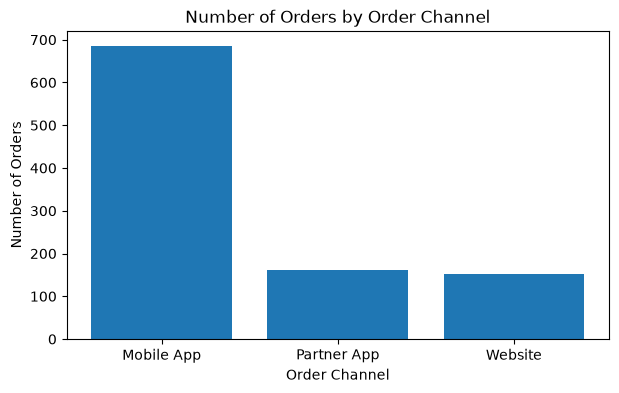

Mobile App is the most used channel and Website is the least used.


In [54]:
channel_counts = work_df["Order Channel"].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(channel_counts.index.astype(str), channel_counts.values)
plt.title("Number of Orders by Order Channel")
plt.xlabel("Order Channel")
plt.ylabel("Number of Orders")
plt.show()

print(f"{channel_counts.idxmax()} is the most used channel and {channel_counts.idxmin()} is the least used.")

*What it suggests:* it shows which channel customers use most, so the company knows where to focus app and website improvements.

### Chart 2 — Number of orders by Payment Method

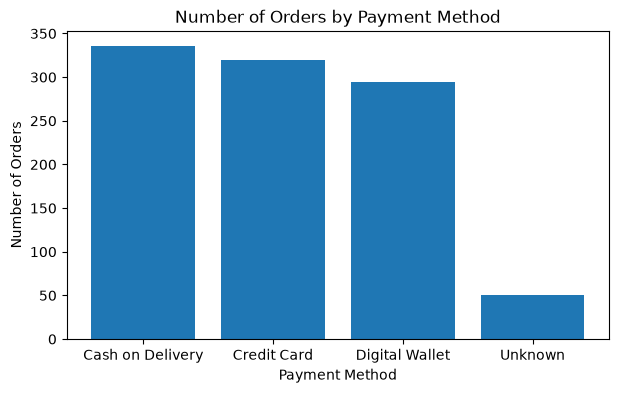

The 'Unknown' bar is the orders whose payment method was missing in the raw data.


In [55]:
payment_all = work_df["Payment Method"].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(payment_all.index.astype(str), payment_all.values)
plt.title("Number of Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.show()

print("The 'Unknown' bar is the orders whose payment method was missing in the raw data.")

*What it suggests:* it shows how customers like to pay. The `Unknown` bar reminds us that some payment methods were not recorded.

### Chart 3 — Average delivery time by Weather Condition

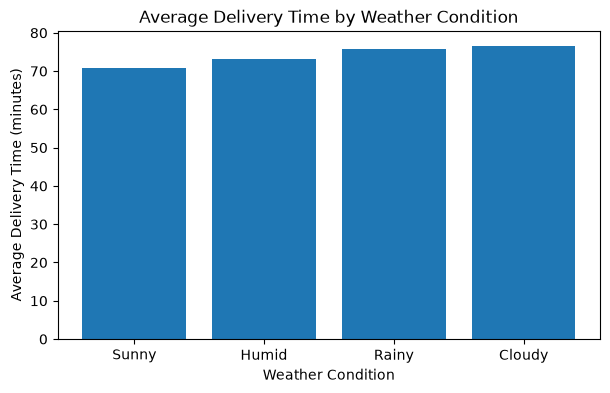

Slowest on average: Cloudy (76.6 min)
Fastest on average: Sunny (70.8 min)


In [56]:
valid_rows = work_df[work_df["Delivery_Time_Minutes"].notna() & ~work_df["suspicious_delivery_time"]]
avg_by_weather = valid_rows.groupby("Weather Condition", observed=True)["Delivery_Time_Minutes"].mean().sort_values()

plt.figure(figsize=(7, 4))
plt.bar(avg_by_weather.index.astype(str), avg_by_weather.values)
plt.title("Average Delivery Time by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Delivery Time (minutes)")
plt.show()

print(f"Slowest on average: {avg_by_weather.idxmax()} ({avg_by_weather.max():.1f} min)")
print(f"Fastest on average: {avg_by_weather.idxmin()} ({avg_by_weather.min():.1f} min)")

*What it suggests:* average delivery time for each weather type. This only shows a **difference**, not a cause. Weather may or may not be the reason, because other things (distance, restaurant, time of day) are not controlled here.

### Chart 4 — Daily order count

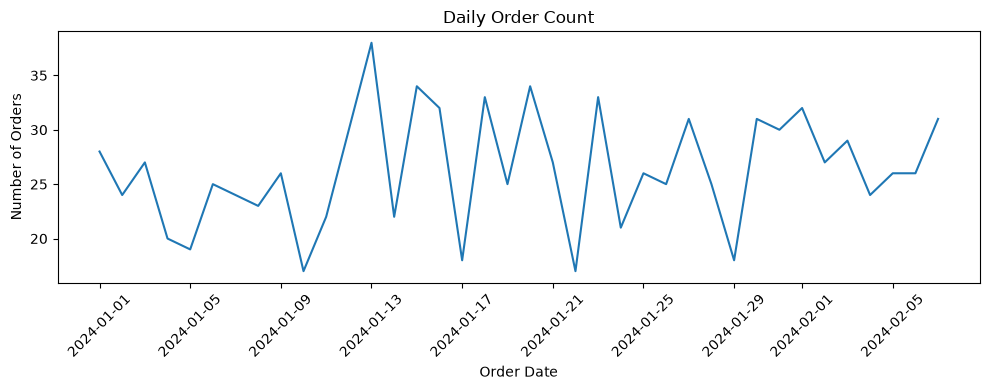

Busiest day: 2024-01-13 with 38 orders
Average orders per day: 26.3


In [57]:
daily_orders = work_df.groupby("Order_Date").size()

plt.figure(figsize=(10, 4))
plt.plot(daily_orders.index, daily_orders.values)
plt.title("Daily Order Count")
plt.xlabel("Order Date")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Busiest day: {daily_orders.idxmax()} with {daily_orders.max()} orders")
print(f"Average orders per day: {daily_orders.mean():.1f}")

*What it suggests:* how order volume moves over time, and which days were busiest.

---
# Task 8 — Validate the Transformed Dataset
Each check prints a result and is saved into a table (`results`). At the end we look at all checks together.

In [58]:
results = []   # every check is stored here

def record(check, passed, details):
    results.append({"Check": check, "Result": "PASS" if passed else "FAIL", "Details": details})

### 8.1 Expected columns

In [59]:
original_cols = list(raw_df.columns)
new_cols = ["Delivery_Time_Minutes", "Order_Date", "Order_Hour", "Platform_Net_Revenue"]

missing_cols = [c for c in original_cols + new_cols if c not in work_df.columns]
print("Missing expected columns:", missing_cols if missing_cols else "None")
record("Expected columns present", len(missing_cols) == 0,
       f"{len(original_cols)} original + {len(new_cols)} derived columns found")

Missing expected columns: None


### 8.2 Data types

In [60]:
datetime_cols = ["Order Date and Time", "Delivery Date and Time"]
money_cols = ["Order Value", "Delivery Fee", "Commission Fee", "Payment Processing Fee",
              "Refunds/Chargebacks", "Delivery_Time_Minutes", "Platform_Net_Revenue"]

bad_dt  = [c for c in datetime_cols if not pd.api.types.is_datetime64_any_dtype(work_df[c])]
bad_num = [c for c in money_cols if not pd.api.types.is_float_dtype(work_df[c])]

print("Datetime columns with wrong type:", bad_dt if bad_dt else "None")
print("Numeric columns with wrong type :", bad_num if bad_num else "None")
record("Datetime columns are datetime", len(bad_dt) == 0, "Order and Delivery timestamps")
record("Financial columns are numeric", len(bad_num) == 0, "5 financial + 2 derived numeric columns")

Datetime columns with wrong type: None
Numeric columns with wrong type : None


### 8.3 Fully duplicated rows

In [61]:
dups_left = work_df[original_cols].duplicated().sum()
dups_in_raw = raw_df.duplicated().sum()
removed = len(raw_df) - len(work_df)

print(f"Duplicate rows in raw_df      : {dups_in_raw}")
print(f"Rows removed during cleaning  : {removed}")
print(f"Duplicate rows left in work_df: {dups_left}")
record("Exact duplicates handled", dups_left == 0 and removed == dups_in_raw,
       f"{dups_in_raw} found in raw, {removed} removed, {dups_left} left")

Duplicate rows in raw_df      : 10
Rows removed during cleaning  : 10
Duplicate rows left in work_df: 0


### 8.4 Repeated Order ID values

In [62]:
repeated_ids = work_df["Order ID"].duplicated().sum()
print(f"Repeated Order IDs left in work_df: {repeated_ids}")
print(f"Unique Order IDs: {work_df['Order ID'].nunique():,} | Rows: {len(work_df):,}")
record("Repeated Order IDs checked", repeated_ids == 0,
       "Every repeated Order ID was an exact duplicate row and was removed in Task 4")

Repeated Order IDs left in work_df: 0
Unique Order IDs: 1,000 | Rows: 1,000


*Explanation:* in Task 4.3 we checked that the repeated Order IDs were identical copies (same transaction loaded twice), so removing them was safe. Nothing with conflicting details was deleted.

### 8.5 No negative delivery durations in valid records

In [63]:
valid_mask = work_df["Delivery_Time_Minutes"].notna() & ~work_df["suspicious_delivery_time"]
negatives_in_valid = (work_df.loc[valid_mask, "Delivery_Time_Minutes"] < 0).sum()
flagged = work_df["suspicious_delivery_time"].sum()

print(f"Negative durations in valid records: {negatives_in_valid}")
print(f"Flagged (suspicious) records        : {flagged}")
record("No negative durations in valid records", negatives_in_valid == 0,
       f"{flagged} suspicious records flagged and documented in Task 5")

# the duration column from Task 4.8 should match our valid durations
same = np.allclose(work_df.loc[valid_mask, "Delivery_Time_Minutes"],
                   work_df.loc[valid_mask, "delivery_duration_min"])
print("Matches the 'delivery_duration_min' column from Task 4.8:", same)
record("Delivery time matches Task 4.8 column", same, "Same values for all valid records")

Negative durations in valid records: 0
Flagged (suspicious) records        : 0
Matches the 'delivery_duration_min' column from Task 4.8: True


### 8.6 Manual check of delivery time (5 records)

In [64]:
sample = work_df[work_df["Delivery_Time_Minutes"].notna()].sample(5, random_state=1)

rows = []
all_ok = True
for index, row in sample.iterrows():
    by_hand = (row["Delivery Date and Time"] - row["Order Date and Time"]).total_seconds() / 60
    matches = abs(by_hand - row["Delivery_Time_Minutes"]) < 0.001
    all_ok = all_ok and matches
    rows.append((row["Order ID"], row["Order Date and Time"], row["Delivery Date and Time"],
                 round(by_hand, 2), round(row["Delivery_Time_Minutes"], 2), matches))

display(pd.DataFrame(rows, columns=["Order ID", "Order time", "Delivery time",
                                    "By hand (min)", "In column (min)", "Match?"]))
record("Delivery time correct (5 manual records)", all_ok, "Hand calculation equals the column")

,Order ID,Order time,Delivery time,By hand (min),In column (min),Match?
0,508,2024-01-15 01:01:01,2024-01-15 02:07:01,66.00,66.00,True
1,819,2024-01-08 23:32:36,2024-01-09 01:18:36,106.00,106.00,True
2,453,2024-01-25 23:44:41,2024-01-26 00:45:41,61.00,61.00,True
3,369,2024-01-02 21:59:35,2024-01-02 22:53:35,54.00,54.00,True
4,243,2024-01-09 02:32:16,2024-01-09 03:11:16,39.00,39.00,True


### 8.7 Manual check of Platform_Net_Revenue (5 records)

In [65]:
complete = work_df[work_df["revenue_parts_available"]].sample(5, random_state=1)

rows = []
all_ok = True
for index, row in complete.iterrows():
    by_hand = row["Commission Fee"] + row["Delivery Fee"] - row["Payment Processing Fee"] - row["Refunds/Chargebacks"]
    matches = abs(by_hand - row["Platform_Net_Revenue"]) < 0.001
    all_ok = all_ok and matches
    rows.append((row["Order ID"], row["Commission Fee"], row["Delivery Fee"],
                 row["Payment Processing Fee"], row["Refunds/Chargebacks"],
                 round(by_hand, 2), round(row["Platform_Net_Revenue"], 2), matches))

display(pd.DataFrame(rows, columns=["Order ID", "Commission", "Delivery Fee", "Processing Fee",
                                    "Refund", "By hand", "In column", "Match?"]))
record("Revenue formula correct (5 manual records)", all_ok, "Hand calculation equals the column")

# rows with a missing part must have a missing revenue
wrongly_filled = work_df.loc[~work_df["revenue_parts_available"], "Platform_Net_Revenue"].notna().sum()
print(f"Rows with a missing part but a revenue value: {wrongly_filled}")
record("Revenue left missing when a part is missing", wrongly_filled == 0, "No zero-filling was done")

,Order ID,Commission,Delivery Fee,Processing Fee,Refund,By hand,In column,Match?
0,456,59.00,0.00,44.00,0.00,15.00,15.00,True
1,552,190.00,40.00,12.00,50.00,168.00,168.00,True
2,972,95.00,40.00,40.00,0.00,95.00,95.00,True
3,695,134.00,30.00,48.00,50.00,66.00,66.00,True
4,689,77.00,20.00,34.00,100.00,-37.00,-37.00,True


Rows with a missing part but a revenue value: 0


### 8.8 Missing values — before and after cleaning

In [66]:
missing_compare = pd.DataFrame({
    "Missing in raw_df (before)": raw_df.isna().sum(),
    "Missing in work_df (after)": work_df[original_cols].isna().sum(),
})
missing_compare["Change"] = missing_compare["Missing in work_df (after)"] - missing_compare["Missing in raw_df (before)"]
display(missing_compare)
print("Payment Method and Discounts and Offers should now be 0 (filled with labels).")
print("Financial columns keep their missing values on purpose (unknown is not zero).")

record("Categorical gaps labelled",
       work_df["Payment Method"].isna().sum() == 0 and work_df["Discounts and Offers"].isna().sum() == 0,
       "Payment Method -> Unknown, Discounts and Offers -> Not Specified")

,Missing in raw_df (before),Missing in work_df (after),Change
Order ID,0,0,0
Customer ID,0,0,0
Restaurant ID,0,0,0
Order Date and Time,0,0,0
Delivery Date and Time,0,0,0
Order Value,41,40,-1
Delivery Fee,50,50,0
Payment Method,50,0,-50
Discounts and Offers,242,0,-242
Commission Fee,40,40,0


Payment Method and Discounts and Offers should now be 0 (filled with labels).
Financial columns keep their missing values on purpose (unknown is not zero).


### 8.9 Records removed, retained and excluded from key calculations

In [67]:
counts = pd.DataFrame([
    ("Original records (raw_df)", len(raw_df)),
    ("Removed (exact duplicates)", len(raw_df) - len(work_df)),
    ("Retained (work_df)", len(work_df)),
    ("Excluded from Order Value metrics (missing value)", work_df["Order Value"].isna().sum()),
    ("Excluded from delivery-time metrics", (~valid_mask).sum()),
    ("Excluded from Platform_Net_Revenue (missing part)", (~work_df["revenue_parts_available"]).sum()),
], columns=["Item", "Records"])
display(counts)

record("Row counts reconcile", len(raw_df) - removed == len(work_df), "Original - removed = retained")

,Item,Records
0,Original records (raw_df),1010
1,Removed (exact duplicates),10
2,Retained (work_df),1000
3,Excluded from Order Value metrics (missing value),40
4,Excluded from delivery-time metrics,0
5,Excluded from Platform_Net_Revenue (missing part),172


### 8.10 Final validation result

In [68]:
results_df = pd.DataFrame(results)
display(results_df)

if (results_df["Result"] == "PASS").all():
    print("All validation checks PASSED.")
else:
    print("Some checks FAILED - look at the table above.")

,Check,Result,Details
0,Expected columns present,PASS,14 original + 4 derived columns found
1,Datetime columns are datetime,PASS,Order and Delivery timestamps
2,Financial columns are numeric,PASS,5 financial + 2 derived numeric columns
3,Exact duplicates handled,PASS,"10 found in raw, 10 removed, 0 left"
4,Repeated Order IDs checked,PASS,Every repeated Order ID was an exact duplicate...
5,No negative durations in valid records,PASS,0 suspicious records flagged and documented in...
6,Delivery time matches Task 4.8 column,PASS,Same values for all valid records
7,Delivery time correct (5 manual records),PASS,Hand calculation equals the column
8,Revenue formula correct (5 manual records),PASS,Hand calculation equals the column
9,Revenue left missing when a part is missing,PASS,No zero-filling was done


All validation checks PASSED.


**Validation principle:** we did not try to make every missing-value count zero. Remaining gaps (mainly fees, refunds and order value) are understood, flagged, and left out of the calculations that need them.

### Save the final cleaned dataset (now with the derived columns)

In [69]:
work_df.to_csv("food_orders_cleaned.csv", index=False)
print("Saved → food_orders_cleaned.csv", work_df.shape)

Saved → food_orders_cleaned.csv (1000, 32)


---
# Final Summary
- **Cleaning:** exact duplicate rows were removed; missing categories were labelled `Unknown` / `Not Specified`; missing money values were kept as missing, not turned into zero.
- **New columns:** `Delivery_Time_Minutes`, `Order_Date`, `Order_Hour`, `Platform_Net_Revenue`.
- **Business answers:** all numbers come from the code cells in Task 6, and each one states how many records were used.
- **Limitation:** order value and revenue totals are partial, because some records have missing values.